# Manufacturing Quality & Yield Analytics

## SECOM Manufacturing Quality Case Study

### Objective

The objective of this analysis is to evaluate manufacturing
process data to identify patterns associated with production
failures, assess process stability, and prioritize process
variables for further quality investigation.

### Business Question

Which process measurements show the strongest relationship
with manufacturing failures, and where should Quality
Operations prioritize further investigation?

### Data Source

UCI Machine Learning Repository — SECOM Dataset.

The dataset contains anonymized semiconductor manufacturing
process measurements and pass/fail production outcomes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

In [29]:
# Loading process measurement data
measurements = pd.read_csv(
    "../data/raw/secom.data",
    sep=r"\s+",
    header=None
)

# Create meaningful neutral column names
measurements.columns = [
    f"Sensor_{i+1:03d}"
    for i in range(measurements.shape[1])
]

measurements.head()

,Sensor_001,Sensor_002,Sensor_003,Sensor_004,Sensor_005,Sensor_006,Sensor_007,Sensor_008,Sensor_009,Sensor_010,Sensor_011,Sensor_012,Sensor_013,Sensor_014,Sensor_015,Sensor_016,Sensor_017,Sensor_018,Sensor_019,Sensor_020,Sensor_021,Sensor_022,Sensor_023,Sensor_024,Sensor_025,Sensor_026,Sensor_027,Sensor_028,Sensor_029,Sensor_030,Sensor_031,Sensor_032,Sensor_033,Sensor_034,Sensor_035,Sensor_036,Sensor_037,Sensor_038,Sensor_039,Sensor_040,Sensor_041,Sensor_042,Sensor_043,Sensor_044,Sensor_045,Sensor_046,Sensor_047,Sensor_048,Sensor_049,Sensor_050,...,Sensor_541,Sensor_542,Sensor_543,Sensor_544,Sensor_545,Sensor_546,Sensor_547,Sensor_548,Sensor_549,Sensor_550,Sensor_551,Sensor_552,Sensor_553,Sensor_554,Sensor_555,Sensor_556,Sensor_557,Sensor_558,Sensor_559,Sensor_560,Sensor_561,Sensor_562,Sensor_563,Sensor_564,Sensor_565,Sensor_566,Sensor_567,Sensor_568,Sensor_569,Sensor_570,Sensor_571,Sensor_572,Sensor_573,Sensor_574,Sensor_575,Sensor_576,Sensor_577,Sensor_578,Sensor_579,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,1.4026,-5419.00,2916.50,-4043.75,751.00,0.8955,1.7730,3.0490,64.2333,2.0222,0.1632,3.5191,83.3971,9.5126,50.6170,64.2588,49.3830,66.3141,86.9555,117.5132,61.29,4.515,70.0,352.7173,10.1841,130.3691,723.3092,1.3072,141.2282,1.0,...,4.0825,11.5074,0.1096,0.0078,0.0026,7.116,1.0616,395.570,75.752,0.4234,12.93,0.78,0.1827,5.7349,0.3363,39.8842,3.2687,1.0297,1.0344,0.4385,0.1039,42.3877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,1.3825,-5441.50,2604.25,-3498.75,-1640.25,1.2973,2.0143,7.3900,68.4222,2.2667,0.2102,3.4171,84.9052,9.7997,50.6596,64.2828,49.3404,64.9193,87.5241,118.1188,78.25,2.773,70.0,352.2445,10.0373,133.1727,724.8264,1.2887,145.8445,1.0,...,2.9799,9.5796,0.1096,0.0078,0.0026,7.116,1.3526,408.798,74.640,0.7193,16.00,1.33,0.2829,7.1196,0.4989,53.1836,3.9139,1.7819,0.9634,0.1745,0.0375,18.1087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,1.4123,-5447.75,2701.75,-4047.00,-1916.50,1.3122,2.0295,7.5788,67.1333,2.3333,0.1734,3.5986,84.7569,8.6590,50.1530,64.1114,49.8470,65.8389,84.7327,118.6128,14.37,5.434,70.0,364.3782,9.8783,131.8027,734.7924,1.2992,141.0845,1.0,...,2.9667,9.3046,0.1096,0.0078,0.0026,7.116,0.7942,411.136,74.654,0.1832,16.16,0.85,0.0857,7.1619,0.3752,23.0713,3.9306,1.1386,1.5021,0.3718,0.1233,24.7524,267.064,0.9032,1.10,0.6219,0.4122,0.2562,0.4119,68.8489,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,1.4011,-5468.25,2648.25,-4515.00,-1657.25,1.3137,2.0038,7.3145,62.9333,2.6444,0.2071,3.3813,84.9105,8.6789,50.5100,64.1125,49.4900,65.1951,86.6867,117.0442,76.90,1.279,70.0,363.0273,9.9305,131.8027,733.8778,1.3027,142.5427,1.0,...,3.2465,7.7754,0.1096,0.0078,0.0026,7.116,1.1650,372.822,72.442,1.8804,131.68,39.33,0.6812,56.9303,17.4781,161.4081,35.3198,54.2917,1.1613,0.7288,0.2710,62.7572,268.228,0.6511,7.32,0.1630,3.5611,0.0670,2.7290,25.0363,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,30

In [28]:
# Loading the quality results

labels = pd.read_csv(
    "../data/raw/secom_labels.data",
    sep=r"\s+",
    header=None
)

labels.columns = ["Result", "Timestamp"]

labels.head()

,Result,Timestamp
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


In [27]:
# Checking that the files align

print("Measurement rows:", measurements.shape[0])
print("Label rows:", labels.shape[0])


Measurement rows: 1567
Label rows: 1567


In [26]:
# Combining the data

df = pd.concat(
    [labels.reset_index(drop=True),
     measurements.reset_index(drop=True)],
    axis=1
)

df.head()

,Result,Timestamp,Sensor_001,Sensor_002,Sensor_003,Sensor_004,Sensor_005,Sensor_006,Sensor_007,Sensor_008,Sensor_009,Sensor_010,Sensor_011,Sensor_012,Sensor_013,Sensor_014,Sensor_015,Sensor_016,Sensor_017,Sensor_018,Sensor_019,Sensor_020,Sensor_021,Sensor_022,Sensor_023,Sensor_024,Sensor_025,Sensor_026,Sensor_027,Sensor_028,Sensor_029,Sensor_030,Sensor_031,Sensor_032,Sensor_033,Sensor_034,Sensor_035,Sensor_036,Sensor_037,Sensor_038,Sensor_039,Sensor_040,Sensor_041,Sensor_042,Sensor_043,Sensor_044,Sensor_045,Sensor_046,Sensor_047,Sensor_048,...,Sensor_541,Sensor_542,Sensor_543,Sensor_544,Sensor_545,Sensor_546,Sensor_547,Sensor_548,Sensor_549,Sensor_550,Sensor_551,Sensor_552,Sensor_553,Sensor_554,Sensor_555,Sensor_556,Sensor_557,Sensor_558,Sensor_559,Sensor_560,Sensor_561,Sensor_562,Sensor_563,Sensor_564,Sensor_565,Sensor_566,Sensor_567,Sensor_568,Sensor_569,Sensor_570,Sensor_571,Sensor_572,Sensor_573,Sensor_574,Sensor_575,Sensor_576,Sensor_577,Sensor_578,Sensor_579,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590
0,-1,19/07/2008 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,1.4026,-5419.00,2916.50,-4043.75,751.00,0.8955,1.7730,3.0490,64.2333,2.0222,0.1632,3.5191,83.3971,9.5126,50.6170,64.2588,49.3830,66.3141,86.9555,117.5132,61.29,4.515,70.0,352.7173,10.1841,130.3691,723.3092,1.3072,...,4.0825,11.5074,0.1096,0.0078,0.0026,7.116,1.0616,395.570,75.752,0.4234,12.93,0.78,0.1827,5.7349,0.3363,39.8842,3.2687,1.0297,1.0344,0.4385,0.1039,42.3877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,-1,19/07/2008 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,1.3825,-5441.50,2604.25,-3498.75,-1640.25,1.2973,2.0143,7.3900,68.4222,2.2667,0.2102,3.4171,84.9052,9.7997,50.6596,64.2828,49.3404,64.9193,87.5241,118.1188,78.25,2.773,70.0,352.2445,10.0373,133.1727,724.8264,1.2887,...,2.9799,9.5796,0.1096,0.0078,0.0026,7.116,1.3526,408.798,74.640,0.7193,16.00,1.33,0.2829,7.1196,0.4989,53.1836,3.9139,1.7819,0.9634,0.1745,0.0375,18.1087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,1,19/07/2008 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,1.4123,-5447.75,2701.75,-4047.00,-1916.50,1.3122,2.0295,7.5788,67.1333,2.3333,0.1734,3.5986,84.7569,8.6590,50.1530,64.1114,49.8470,65.8389,84.7327,118.6128,14.37,5.434,70.0,364.3782,9.8783,131.8027,734.7924,1.2992,...,2.9667,9.3046,0.1096,0.0078,0.0026,7.116,0.7942,411.136,74.654,0.1832,16.16,0.85,0.0857,7.1619,0.3752,23.0713,3.9306,1.1386,1.5021,0.3718,0.1233,24.7524,267.064,0.9032,1.10,0.6219,0.4122,0.2562,0.4119,68.8489,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,-1,19/07/2008 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,1.4011,-5468.25,2648.25,-4515.00,-1657.25,1.3137,2.0038,7.3145,62.9333,2.6444,0.2071,3.3813,84.9105,8.6789,50.5100,64.1125,49.4900,65.1951,86.6867,117.0442,76.90,1.279,70.0,363.0273,9.9305,131.8027,733.8778,1.3027,...,3.2465,7.7754,0.1096,0.0078,0.0026,7.116,1.1650,372.822,72.442,1.8804,131.68,39.33,0.6812,56.9303,17.4781,161.4081,35.3198,54.2917,1.1613,0.7288,0.2710,62.7572,268.228,0.6511,7.32,0.1630,3.5611,0.0670,2.7290,25.0363,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544

In [9]:
df.shape

(1567, 592)

In [25]:
# Converting the timestamp properly

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    format="%d/%m/%Y %H:%M:%S"
)

In [11]:
df[["Timestamp", "Result"]].head()

,Timestamp,Result
0,2008-07-19 11:55:00,-1
1,2008-07-19 12:32:00,-1
2,2008-07-19 13:17:00,1
3,2008-07-19 14:43:00,-1
4,2008-07-19 15:22:00,-1


In [ ]:
# Creating understandable Pass/Fail fields

df["Quality_Status"] = df["Result"].map({
    -1: "Pass",
     1: "Fail"
})

C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\85094760.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Quality_Status"] = df["Result"].map({


In [13]:
df["Failure_Flag"] = (df["Result"] == 1).astype(int)

C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\1122528985.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Failure_Flag"] = (df["Result"] == 1).astype(int)


In [14]:
df["Failure_Flag"].mean()

np.float64(0.06636885768985322)

In [ ]:
# Creating Time Variables

df["Date"] = df["Timestamp"].dt.date
df["Year"] = df["Timestamp"].dt.year
df["Month"] = df["Timestamp"].dt.month
df["Month_Name"] = df["Timestamp"].dt.month_name()
df["Week"] = df["Timestamp"].dt.isocalendar().week
df["Day"] = df["Timestamp"].dt.day
df["Day_of_Week"] = df["Timestamp"].dt.day_name()
df["Hour"] = df["Timestamp"].dt.hour

In [ ]:
# Creating time-based features

time_features = pd.DataFrame({
    "Date": df["Timestamp"].dt.date,
    "Year": df["Timestamp"].dt.year,
    "Month": df["Timestamp"].dt.month,
    "Month_Name": df["Timestamp"].dt.month_name(),
    "Week": df["Timestamp"].dt.isocalendar().week,
    "Day": df["Timestamp"].dt.day,
    "Day_of_Week": df["Timestamp"].dt.day_name(),
    "Hour": df["Timestamp"].dt.hour
}, index=df.index)

df = pd.concat([df, time_features], axis=1).copy()

df.head()

,Result,Timestamp,Sensor_001,Sensor_002,Sensor_003,Sensor_004,Sensor_005,Sensor_006,Sensor_007,Sensor_008,Sensor_009,Sensor_010,Sensor_011,Sensor_012,Sensor_013,Sensor_014,Sensor_015,Sensor_016,Sensor_017,Sensor_018,Sensor_019,Sensor_020,Sensor_021,Sensor_022,Sensor_023,Sensor_024,Sensor_025,Sensor_026,Sensor_027,Sensor_028,Sensor_029,Sensor_030,Sensor_031,Sensor_032,Sensor_033,Sensor_034,Sensor_035,Sensor_036,Sensor_037,Sensor_038,Sensor_039,Sensor_040,Sensor_041,Sensor_042,Sensor_043,Sensor_044,Sensor_045,Sensor_046,Sensor_047,Sensor_048,...,Sensor_567,Sensor_568,Sensor_569,Sensor_570,Sensor_571,Sensor_572,Sensor_573,Sensor_574,Sensor_575,Sensor_576,Sensor_577,Sensor_578,Sensor_579,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589,Sensor_590,Quality_Status,Failure_Flag,Date,Year,Month,Month_Name,Week,Day,Day_of_Week,Hour,Date,Year,Month,Month_Name,Week,Day,Day_of_Week,Hour,Date,Year,Month,Month_Name,Week,Day,Day_of_Week,Hour
0,-1,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,1.4026,-5419.00,2916.50,-4043.75,751.00,0.8955,1.7730,3.0490,64.2333,2.0222,0.1632,3.5191,83.3971,9.5126,50.6170,64.2588,49.3830,66.3141,86.9555,117.5132,61.29,4.515,70.0,352.7173,10.1841,130.3691,723.3092,1.3072,...,NaN,NaN,NaN,NaN,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,Pass,0,2008-07-19,2008,7,July,29,19,Saturday,11,2008-07-19,2008,7,July,29,19,Saturday,11,2008-07-19,2008,7,July,29,19,Saturday,11
1,-1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,1.3825,-5441.50,2604.25,-3498.75,-1640.25,1.2973,2.0143,7.3900,68.4222,2.2667,0.2102,3.4171,84.9052,9.7997,50.6596,64.2828,49.3404,64.9193,87.5241,118.1188,78.25,2.773,70.0,352.2445,10.0373,133.1727,724.8264,1.2887,...,NaN,NaN,NaN,NaN,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,Pass,0,2008-07-19,2008,7,July,29,19,Saturday,12,2008-07-19,2008,7,July,29,19,Saturday,12,2008-07-19,2008,7,July,29,19,Saturday,12
2,1,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,1.4123,-5447.75,2701.75,-4047.00,-1916.50,1.3122,2.0295,7.5788,67.1333,2.3333,0.1734,3.5986,84.7569,8.6590,50.1530,64.1114,49.8470,65.8389,84.7327,118.6128,14.37,5.434,70.0,364.3782,9.8783,131.8027,734.7924,1.2992,...,0.4122,0.2562,0.4119,68.8489,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,Fail,1,2008-07-19,2008,7,July,29,19,Saturday,13,2008-07-19,2008,7,July,29,19,Saturday,13,2008-07-19,2008,7,July,29,19,Saturday,13
3,-1,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,1.4011,-5468.25,2648.25,-4515.00,-1657.25,1.3137,2.0038,7.3145,62.9333,2.6444,0.2071,3.3813,84.9105,8.6789,50.5100,64.1125,49.4900,65.1951,86.6867,117.0442,76.90,1.279,70.0,363.0273,9.9305,131.8027,733.8778,1.3027,...,3.5611,0.0670,2.7290,25.0363,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,Pass,0,2008-07-19,2008,7,July,29,19,Saturday,14,2008-07-19,2008,7,July,29,19,Saturday,14,2008-07-19,2008,7,July,29,19,Saturday,14
4,-1,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,-0.0072,0.9569,201.9424,0.0,10.5661,420.5925,10.3387,0.9735,191.6037,12.4735,1.3888,-5476.25,2635.25,-3987.50,117.00,1.2887,1.9912,7.2748,62.8333,3.15

In [20]:
# First QA Checks

print("Dataset dimensions:", df.shape)

print(
    "\nTotal missing values:",
    df.isnull().sum().sum()
)

print(
    "\nDuplicate rows:",
    df.duplicated().sum()
)

print("\nQuality results:")
print(df["Quality_Status"].value_counts())

Dataset dimensions: (1567, 610)

Total missing values: 41951

Duplicate rows: 0

Quality results:
Quality_Status
Pass    1463
Fail     104
Name: count, dtype: int64


In [22]:
# Calculating Percentage

quality_summary = (
    df["Quality_Status"]
    .value_counts()
    .to_frame("Count")
)

quality_summary["Percentage"] = (
    quality_summary["Count"] / len(df) * 100
)

quality_summary

,Count,Percentage
Quality_Status,,
Pass,1463,93.363114
Fail,104,6.636886


# QA KPI
Yield
\[
Yield=\frac{1463}{1567}\times100
\]
≈ 93.36%

Failure Rate
\[
Failure\ Rate=\frac{104}{1567}\times100
\]
≈ 6.64%

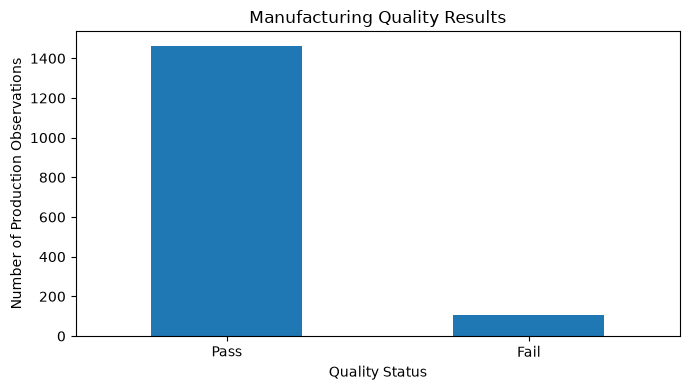

In [31]:
# Creating a Simple Pass/Faill visualization 

quality_summary["Count"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Manufacturing Quality Results")
plt.xlabel("Quality Status")
plt.ylabel("Number of Production Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Cleaning manufacturing data

In [32]:
# Measure missingness by Sensor

sensor_cols = [col for col in df.columns if col.startswith("Sensor_")]

missing_summary = pd.DataFrame({
    "Missing_Count": df[sensor_cols].isnull().sum(),
    "Missing_Percent": df[sensor_cols].isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_summary.head(15)

,Missing_Count,Missing_Percent
Sensor_293,1429,91.193363
Sensor_294,1429,91.193363
Sensor_159,1429,91.193363
Sensor_158,1429,91.193363
Sensor_493,1341,85.577537
Sensor_086,1341,85.577537
Sensor_359,1341,85.577537
Sensor_221,1341,85.577537
Sensor_245,1018,64.964901
Sensor_518,1018,64.964901


In [33]:
missing_summary["Missing_Percent"].describe()

count    590.000000
mean       4.537549
std       15.433986
min        0.000000
25%        0.127632
50%        0.382897
75%        0.574346
max       91.193363
Name: Missing_Percent, dtype: float64

In [ ]:
# sensors with excessive missing data ; Diff thresholds

for threshold in [10, 20, 30, 40, 50]:
    count = (missing_summary["Missing_Percent"] > threshold).sum()
    print(f"Sensors > {threshold}% missing: {count}")

Sensors > 10% missing: 52
Sensors > 20% missing: 32
Sensors > 30% missing: 32
Sensors > 40% missing: 32
Sensors > 50% missing: 28


In [35]:
# Remove sensors with more than 40% missing observations

high_missing_cols = missing_summary[
    missing_summary["Missing_Percent"] > 40
].index.tolist()

print("Sensors removed for >40% missing:", len(high_missing_cols))

Sensors removed for >40% missing: 32


In [36]:
# Finding constant variables

unique_counts = df[sensor_cols].nunique(dropna=True)

constant_cols = unique_counts[
    unique_counts <= 1
].index.tolist()

print("Constant sensors:", len(constant_cols))

Constant sensors: 116


In [37]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [38]:
# Check impossible/infinite values

numeric_sensors = df[sensor_cols]

infinite_count = np.isinf(
    numeric_sensors.to_numpy()
).sum()

print("Infinite values:", infinite_count)

Infinite values: 0


In [39]:
numeric_sensors.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
Sensor_001,1561.0,3014.452896,73.621787,2743.2400,2966.2600,3011.4900,3056.6500,3356.3500
Sensor_002,1560.0,2495.850231,80.407705,2158.7500,2452.2475,2499.4050,2538.8225,2846.4400
Sensor_003,1553.0,2200.547318,29.513152,2060.6600,2181.0444,2201.0667,2218.0555,2315.2667
Sensor_004,1553.0,1396.376627,441.691640,0.0000,1081.8758,1285.2144,1591.2235,3715.0417
Sensor_005,1553.0,4.197013,56.355540,0.6815,1.0177,1.3168,1.5257,1114.5366
Sensor_006,1553.0,100.000000,0.000000,100.0000,100.0000,100.0000,100.0000,100.0000
Sensor_007,1553.0,101.112908,6.237214,82.1311,97.9200,101.5122,104.5867,129.2522
Sensor_008,1558.0,0.121822,0.008961,0.0000,0.1211,0.1224,0.1238,0.1286
Sensor_009,1565.0,1.462862,0.073897,1.1910,1.4112,1.4616,1.5169,1.6564
Sensor_010,1565.0,-0.000841,0.015116,-0.0534,-0.0108,-0.0013,0.0084,0.0749


In [41]:
# Remove unuseable sensorscols_to_remove = list(
cols_to_remove = list(
    set(high_missing_cols + constant_cols)
)

print("Total sensors being removed:", len(cols_to_remove))

Total sensors being removed: 148


In [42]:
df_clean = df.drop(columns=cols_to_remove).copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1567, 592)
Cleaned shape: (1567, 444)


In [43]:
# Dealing with remaining missing measurements

remaining_sensor_cols = [
    col for col in df_clean.columns
    if col.startswith("Sensor_")
]

remaining_missing = (
    df_clean[remaining_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print("Remaining missing values:", remaining_missing)

Remaining missing values: 8008


In [44]:
sensor_medians = df_clean[
    remaining_sensor_cols
].median()

df_clean[remaining_sensor_cols] = (
    df_clean[remaining_sensor_cols]
    .fillna(sensor_medians)
)

In [45]:
df_clean[
    remaining_sensor_cols
].isnull().sum().sum()

np.int64(0)

In [48]:
print(df_clean.columns.tolist()[:20])
print("\nQuality_Status exists:", "Quality_Status" in df_clean.columns)

['Result', 'Timestamp', 'Sensor_001', 'Sensor_002', 'Sensor_003', 'Sensor_004', 'Sensor_005', 'Sensor_007', 'Sensor_008', 'Sensor_009', 'Sensor_010', 'Sensor_011', 'Sensor_012', 'Sensor_013', 'Sensor_015', 'Sensor_016', 'Sensor_017', 'Sensor_018', 'Sensor_019', 'Sensor_020']

Quality_Status exists: False


In [49]:
df_clean["Quality_Status"] = df_clean["Result"].map({
    -1: "Pass",
     1: "Fail"
})

df_clean["Failure_Flag"] = (df_clean["Result"] == 1).astype(int)

C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\2453251096.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean["Quality_Status"] = df_clean["Result"].map({
C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\2453251096.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean["Failure_Flag"] = (df_clean["Result"] == 1).astype(int)


In [50]:
df_clean[["Result", "Quality_Status", "Failure_Flag"]].head(10)

,Result,Quality_Status,Failure_Flag
0,-1,Pass,0
1,-1,Pass,0
2,1,Fail,1
3,-1,Pass,0
4,-1,Pass,0
5,-1,Pass,0
6,-1,Pass,0
7,-1,Pass,0
8,-1,Pass,0
9,-1,Pass,0


In [51]:
df_clean["Quality_Status"].value_counts()

Quality_Status
Pass    1463
Fail     104
Name: count, dtype: int64

In [52]:
df_clean["Failure_Flag"].mean() * 100

np.float64(6.636885768985322)

In [54]:
# Make sure Timestamp is datetime
df_clean["Timestamp"] = pd.to_datetime(
    df_clean["Timestamp"],
    errors="coerce"
)

# Create analytical time fields
df_clean["Date"] = df_clean["Timestamp"].dt.date
df_clean["Year"] = df_clean["Timestamp"].dt.year
df_clean["Month"] = df_clean["Timestamp"].dt.month
df_clean["Month_Name"] = df_clean["Timestamp"].dt.month_name()
df_clean["Week"] = df_clean["Timestamp"].dt.isocalendar().week
df_clean["Day"] = df_clean["Timestamp"].dt.day
df_clean["Day_of_Week"] = df_clean["Timestamp"].dt.day_name()
df_clean["Hour"] = df_clean["Timestamp"].dt.hour

C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\863139943.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clean["Timestamp"] = pd.to_datetime(
C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\863139943.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_clean["Date"] = df_clean["Timestamp"].dt.date
C:\Users\flexd\AppData\Local\Temp\ipykernel_30716\863139943.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe =

In [55]:
required_cols = [
    "Timestamp",
    "Result",
    "Quality_Status",
    "Failure_Flag",
    "Date",
    "Year",
    "Month",
    "Week",
    "Day_of_Week",
    "Hour"
]

for col in required_cols:
    print(f"{col:20} {'✓' if col in df_clean.columns else 'MISSING'}")

Timestamp            ✓
Result               ✓
Quality_Status       ✓
Failure_Flag         ✓
Date                 ✓
Year                 ✓
Month                ✓
Week                 ✓
Day_of_Week          ✓
Hour                 ✓


In [56]:
df_clean[
    [
        "Timestamp",
        "Date",
        "Year",
        "Month",
        "Week",
        "Day_of_Week",
        "Hour",
        "Quality_Status"
    ]
].head(10)

,Timestamp,Date,Year,Month,Week,Day_of_Week,Hour,Quality_Status
0,2008-07-19 11:55:00,2008-07-19,2008,7,29,Saturday,11,Pass
1,2008-07-19 12:32:00,2008-07-19,2008,7,29,Saturday,12,Pass
2,2008-07-19 13:17:00,2008-07-19,2008,7,29,Saturday,13,Fail
3,2008-07-19 14:43:00,2008-07-19,2008,7,29,Saturday,14,Pass
4,2008-07-19 15:22:00,2008-07-19,2008,7,29,Saturday,15,Pass
5,2008-07-19 17:53:00,2008-07-19,2008,7,29,Saturday,17,Pass
6,2008-07-19 19:44:00,2008-07-19,2008,7,29,Saturday,19,Pass
7,2008-07-19 19:45:00,2008-07-19,2008,7,29,Saturday,19,Pass
8,2008-07-19 20:24:00,2008-07-19,2008,7,29,Saturday,20,Pass
9,2008-07-19 21:35:00,2008-07-19,2008,7,29,Saturday,21,Pass


In [57]:
print(df_clean["Quality_Status"].value_counts())

print(
    "\nFailure Rate:",
    round(df_clean["Failure_Flag"].mean() * 100, 2),
    "%"
)

print(
    "\nMissing timestamps:",
    df_clean["Timestamp"].isna().sum()
)

Quality_Status
Pass    1463
Fail     104
Name: count, dtype: int64

Failure Rate: 6.64 %

Missing timestamps: 0


In [58]:
# Creating a Data Quality Summary

data_quality_summary = pd.DataFrame({
    "Metric": [
        "Original Observations",
        "Original Sensor Variables",
        "Total Missing Values (Raw)",
        "Duplicate Records",
        "Sensors >40% Missing",
        "Constant Sensors",
        "Sensors Removed",
        "Remaining Sensor Variables",
        "Final Observations",
        "Remaining Missing Values"
    ],

    "Value": [
        len(df),
        len(sensor_cols),
        df[sensor_cols].isnull().sum().sum(),
        duplicate_count,
        len(high_missing_cols),
        len(constant_cols),
        len(cols_to_remove),
        len(remaining_sensor_cols),
        len(df_clean),
        df_clean[remaining_sensor_cols].isnull().sum().sum()
    ]
})

data_quality_summary

,Metric,Value
0,Original Observations,1567
1,Original Sensor Variables,590
2,Total Missing Values (Raw),41951
3,Duplicate Records,0
4,Sensors >40% Missing,32
5,Constant Sensors,116
6,Sensors Removed,148
7,Remaining Sensor Variables,442
8,Final Observations,1567
9,Remaining Missing Values,0


In [65]:
# Saving the Clean Analytical Data set & Quality Summary

df_clean.to_csv(
    "../data/processed/secom_quality_clean.csv",
    index=False
)
# and Quality Summary

data_quality_summary.to_csv(
    "../data/processed/data_quality_summary.csv",
    index=False
)

## QA investigation

In [66]:
# Establish baseline performance

total_units = len(df_clean)
passed_units = (df_clean["Quality_Status"] == "Pass").sum()
failed_units = (df_clean["Quality_Status"] == "Fail").sum()

yield_rate = passed_units / total_units * 100
failure_rate = failed_units / total_units * 100

print(f"Total observations: {total_units:,}")
print(f"Passed: {passed_units:,}")
print(f"Failed: {failed_units:,}")
print(f"Yield: {yield_rate:.2f}%")
print(f"Failure Rate: {failure_rate:.2f}%")

Total observations: 1,567
Passed: 1,463
Failed: 104
Yield: 93.36%
Failure Rate: 6.64%


In [68]:
# Analyzing quality over time

print("Start:", df_clean["Timestamp"].min())
print("End:", df_clean["Timestamp"].max())

daily_quality = (
    df_clean
    .groupby("Date")
    .agg(
        Total_Units=("Failure_Flag", "size"),
        Failures=("Failure_Flag", "sum"),
        Failure_Rate=("Failure_Flag", "mean")
    )
    .reset_index()
)

daily_quality["Failure_Rate"] *= 100

daily_quality.head()

Start: 2008-07-19 11:55:00
End: 2008-10-17 06:07:00


,Date,Total_Units,Failures,Failure_Rate
0,2008-07-19,12,3,25.0
1,2008-07-20,1,0,0.0
2,2008-07-21,2,1,50.0
3,2008-07-22,6,0,0.0
4,2008-07-23,2,0,0.0


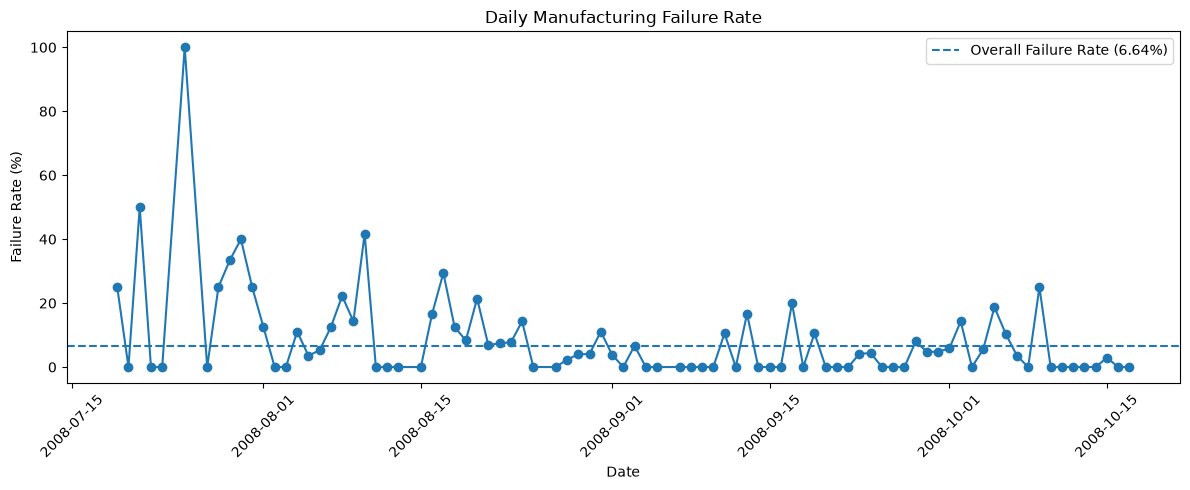

In [ ]:
# Creating a Simple Plot to show quality over time


plt.figure(figsize=(12, 5))

plt.plot(
    daily_quality["Date"],
    daily_quality["Failure_Rate"],
    marker="o"
)

plt.axhline(
    failure_rate,
    linestyle="--",
    label=f"Overall Failure Rate ({failure_rate:.2f}%)"
)

plt.title("Daily Manufacturing Failure Rate")
plt.xlabel("Date")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Checking production volume alongside it

daily_quality.sort_values(
    "Failure_Rate",
    ascending=False
).head(10)

,Date,Total_Units,Failures,Failure_Rate
5,2008-07-25,1,1,100.000000
2,2008-07-21,2,1,50.000000
20,2008-08-10,12,5,41.666667
9,2008-07-30,5,2,40.000000
8,2008-07-29,12,4,33.333333
26,2008-08-17,17,5,29.411765
10,2008-07-31,4,1,25.000000
7,2008-07-28,8,2,25.000000
77,2008-10-09,8,2,25.000000
0,2008-07-19,12,3,25.000000


In [ ]:
# Analyzing hour of day

hourly_quality = (
    df_clean
    .groupby("Hour")
    .agg(
        Total_Units=("Failure_Flag", "size"),
        Failures=("Failure_Flag", "sum"),
        Failure_Rate=("Failure_Flag", "mean")
    )
    .reset_index()
)

hourly_quality["Failure_Rate"] *= 100

hourly_quality

,Hour,Total_Units,Failures,Failure_Rate
0,0,65,3,4.615385
1,1,42,3,7.142857
2,2,60,3,5.000000
3,3,70,5,7.142857
4,4,65,6,9.230769
5,5,74,4,5.405405
6,6,62,5,8.064516
7,7,73,3,4.109589
8,8,64,3,4.687500
9,9,55,6,10.909091


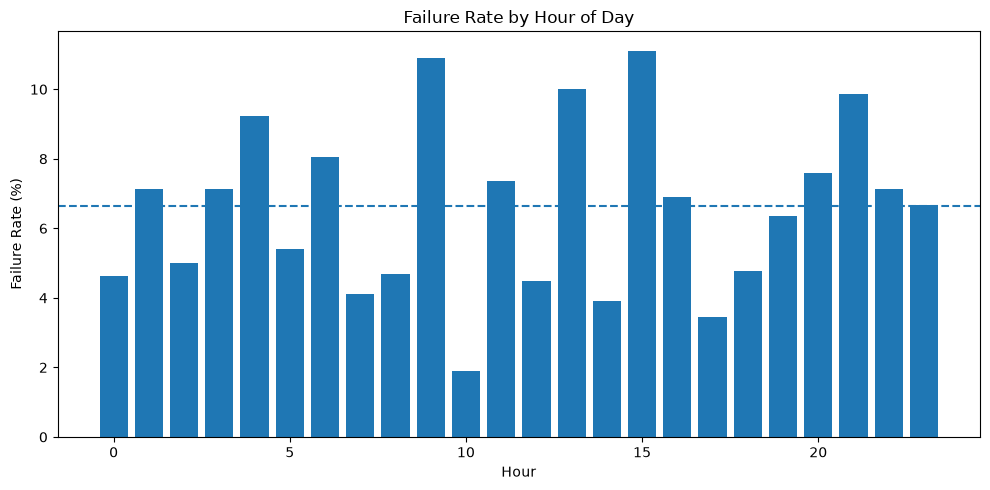

In [73]:
# Plot to show failure rate by hour of day

plt.figure(figsize=(10, 5))

plt.bar(
    hourly_quality["Hour"],
    hourly_quality["Failure_Rate"]
)

plt.axhline(
    failure_rate,
    linestyle="--"
)

plt.title("Failure Rate by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.show()

## *Finding the top process variables associated with Failures

In [74]:
# Finding the top process variables

sensor_cols_clean = [
    col for col in df_clean.columns
    if col.startswith("Sensor_")
]

results = []

for sensor in sensor_cols_clean:

    pass_values = df_clean.loc[
        df_clean["Quality_Status"] == "Pass", sensor
    ]

    fail_values = df_clean.loc[
        df_clean["Quality_Status"] == "Fail", sensor
    ]

    pass_mean = pass_values.mean()
    fail_mean = fail_values.mean()

    overall_std = df_clean[sensor].std()

    if overall_std != 0:
        standardized_difference = (
            fail_mean - pass_mean
        ) / overall_std

        results.append([
            sensor,
            pass_mean,
            fail_mean,
            standardized_difference,
            abs(standardized_difference)
        ])


sensor_analysis = pd.DataFrame(
    results,
    columns=[
        "Sensor",
        "Pass_Mean",
        "Fail_Mean",
        "Standardized_Difference",
        "Absolute_Difference"
    ]
)

sensor_analysis = sensor_analysis.sort_values(
    "Absolute_Difference",
    ascending=False
)

sensor_analysis.head(10)

,Sensor,Pass_Mean,Fail_Mean,Standardized_Difference,Absolute_Difference
54,Sensor_060,2.555731,8.515123,0.626524,0.626524
93,Sensor_104,-0.009913,-0.008053,0.607336,0.607336
385,Sensor_511,54.430401,74.347949,0.528752,0.528752
275,Sensor_349,0.024263,0.030448,0.525317,0.525317
328,Sensor_432,21.187933,38.707342,0.481663,0.481663
331,Sensor_435,13.716830,28.954783,0.447025,0.447025
327,Sensor_431,17.364169,33.156115,0.438203,0.438203
19,Sensor_022,-5636.360219,-5363.822115,0.435065,0.435065
332,Sensor_436,8.373389,23.306973,0.434770,0.434770
26,Sensor_029,69.597730,68.111542,-0.429659,0.429659


In [75]:
# Keep only the Top 5

top_5_sensors = sensor_analysis.head(5)["Sensor"].tolist()

print("Top 5 candidate process variables:")

for sensor in top_5_sensors:
    print(sensor)

Top 5 candidate process variables:
Sensor_060
Sensor_104
Sensor_511
Sensor_349
Sensor_432


In [79]:
# Saving the Analysis

sensor_analysis.head(10).to_csv(
    "../data/processed/top_process_variables.csv",
    index=False
)

In [80]:
plt.savefig(
    "../visuals/top_process_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

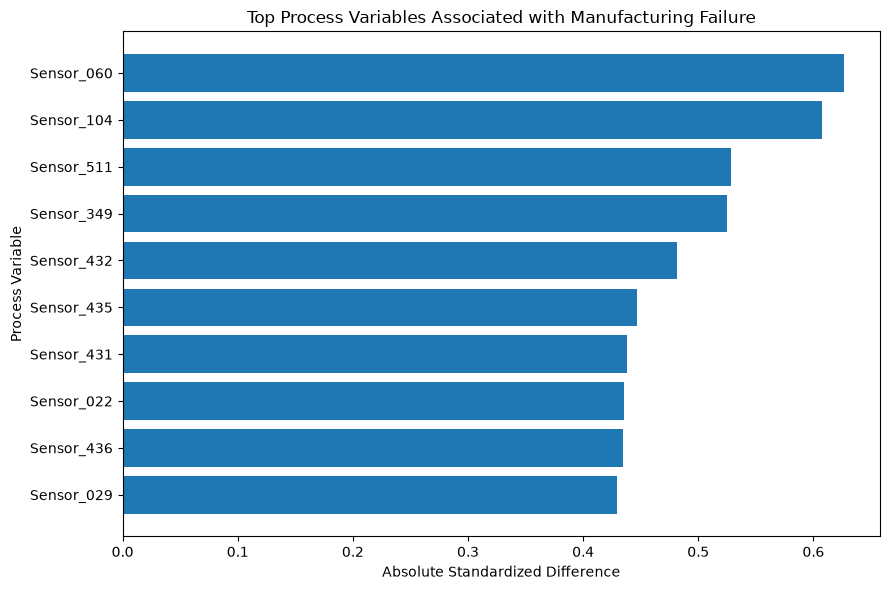

In [ ]:
# visualizing the standardized differences

top10 = sensor_analysis.head(10).sort_values(
    "Absolute_Difference"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top10["Sensor"],
    top10["Absolute_Difference"]
)

plt.title(
    "Top Process Variables Associated with Manufacturing Failure"
)

plt.xlabel("Absolute Standardized Difference")
plt.ylabel("Process Variable")

plt.tight_layout()

plt.savefig(
    "../visuals/top_process_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Identifying the number 1 variable to investigate

top_sensor = top_5_sensors[0]

print("Primary variable for investigation:", top_sensor)

Primary variable for investigation: Sensor_060


In [84]:
# Comparing it between Pass and Fail

comparison = (
    df_clean
    .groupby("Quality_Status")[top_sensor]
    .agg(["count", "mean", "median", "std"])
)

comparison

,count,mean,median,std
Quality_Status,,,,
Fail,104,8.515123,5.5223,10.802344
Pass,1463,2.555731,0.7482,9.291469


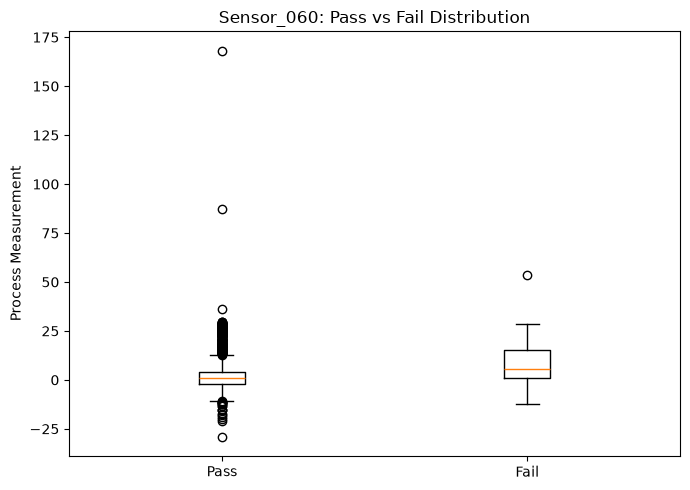

In [85]:
# Pass and Fail Box Chart

pass_data = df_clean.loc[
    df_clean["Quality_Status"] == "Pass",
    top_sensor
]

fail_data = df_clean.loc[
    df_clean["Quality_Status"] == "Fail",
    top_sensor
]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [pass_data, fail_data],
    tick_labels=["Pass", "Fail"]
)

plt.title(
    f"{top_sensor}: Pass vs Fail Distribution"
)

plt.ylabel("Process Measurement")

plt.tight_layout()

plt.savefig(
    "../visuals/pass_fail_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Simple SPC Chart

Process Mean: 2.951
UCL: 31.487
LCL: -25.584


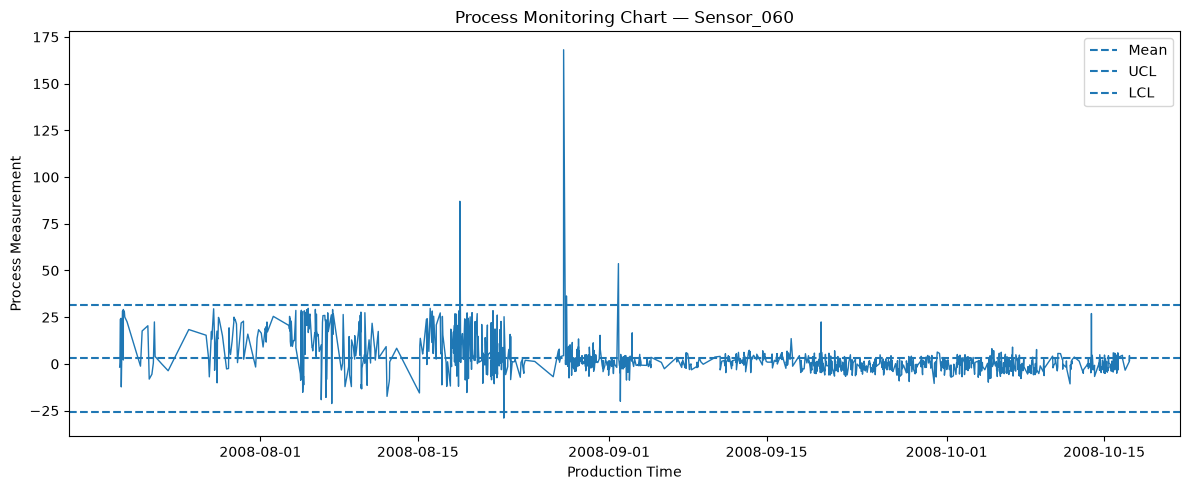

In [90]:
# Sort by time

spc_data = (
    df_clean[
        ["Timestamp", top_sensor, "Quality_Status"]
    ]
    .sort_values("Timestamp")
    .copy()
)

# Calculate center line and 3-sigma limits:

process_mean = spc_data[top_sensor].mean()
process_std = spc_data[top_sensor].std()

ucl = process_mean + 3 * process_std
lcl = process_mean - 3 * process_std

print("Process Mean:", round(process_mean, 3))
print("UCL:", round(ucl, 3))
print("LCL:", round(lcl, 3))

# Creating the Chart

plt.figure(figsize=(12, 5))

plt.plot(
    spc_data["Timestamp"],
    spc_data[top_sensor],
    linewidth=1
)

plt.axhline(
    process_mean,
    linestyle="--",
    label="Mean"
)

plt.axhline(
    ucl,
    linestyle="--",
    label="UCL"
)

plt.axhline(
    lcl,
    linestyle="--",
    label="LCL"
)

plt.title(
    f"Process Monitoring Chart — {top_sensor}"
)

plt.xlabel("Production Time")
plt.ylabel("Process Measurement")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../visuals/process_control_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Count observations beyond the exploratory limits

spc_data["Outside_Control_Limits"] = (
    (spc_data[top_sensor] > ucl) |
    (spc_data[top_sensor] < lcl)
)

print(
    "Observations outside control limits:",
    spc_data["Outside_Control_Limits"].sum()
)

Observations outside control limits: 5


In [ ]:
# checking whether those observations contain failures

pd.crosstab(
    spc_data["Outside_Control_Limits"],
    spc_data["Quality_Status"]
)

Quality_Status,Fail,Pass
Outside_Control_Limits,,
False,103,1459
True,1,4


In [94]:
# Saving final analysis dataset

powerbi_cols = [
    "Timestamp",
    "Date",
    "Year",
    "Month",
    "Month_Name",
    "Week",
    "Day_of_Week",
    "Hour",
    "Quality_Status",
    "Failure_Flag"
] + top_5_sensors

powerbi_df = df_clean[powerbi_cols].copy()

powerbi_df.to_csv(
    "../data/processed/powerbi_quality_data.csv",
    index=False
)

In [97]:
# Create final quality analysis summary

final_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Pass",
        "Fail",
        "Yield Rate (%)",
        "Failure Rate (%)",
        "Primary Candidate Variable",
        "Process Mean",
        "Upper Control Limit",
        "Lower Control Limit",
        "Observations Outside Control Limits"
    ],
    "Value": [
        len(df_clean),
        (df_clean["Quality_Status"] == "Pass").sum(),
        (df_clean["Quality_Status"] == "Fail").sum(),
        round((1 - df_clean["Failure_Flag"].mean()) * 100, 2),
        round(df_clean["Failure_Flag"].mean() * 100, 2),
        "Sensor_060",
        round(process_mean, 3),
        round(ucl, 3),
        round(lcl, 3),
        int(spc_data["Outside_Control_Limits"].sum())
    ]
})

final_summary

,Metric,Value
0,Total Observations,1567
1,Pass,1463
2,Fail,104
3,Yield Rate (%),93.36
4,Failure Rate (%),6.64
5,Primary Candidate Variable,Sensor_060
6,Process Mean,2.951
7,Upper Control Limit,31.487
8,Lower Control Limit,-25.584
9,Observations Outside Control Limits,5


In [98]:
final_summary.to_csv(
    "../data/processed/final_quality_summary.csv",
    index=False
)

print("Final quality summary saved.")

Final quality summary saved.
